In [2]:

from tensorflow.keras.preprocessing.image import ImageDataGenerator
 
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)
 
val_test_datagen = ImageDataGenerator(rescale=1./255)
 
train_data = train_datagen.flow_from_directory(
    'train_mini',
    target_size=(500, 500),
    batch_size=8,
    class_mode='categorical'
)
 
validation_data = val_test_datagen.flow_from_directory(
    'test_mini',
    target_size=(500, 500),
    batch_size=8,
    class_mode='categorical'
)
 
test_data = val_test_datagen.flow_from_directory(
    'test_mini',
    target_size=(500, 500),
    batch_size=8,
    class_mode='categorical'
)          

Found 100 images belonging to 2 classes.
Found 97 images belonging to 2 classes.
Found 97 images belonging to 2 classes.


In [5]:
from tensorflow.keras.applications import InceptionResNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

# Load Inception-ResNetV2 with pre-trained ImageNet weights, without the top classification layer
base_model = InceptionResNetV2(input_shape=(500, 500, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Freeze the base model

# Add custom layers on top of the base model
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)
predictions = Dense(train_data.num_classes, activation='softmax')(x)

# Define the model
model = Model(inputs=base_model.input, outputs=predictions)

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])


219055592/219055592 ━━━━━━━━━━━━━━━━━━━━ 41s 0us/step


In [8]:
history = model.fit(
    train_data,
    epochs=10,
    validation_data=validation_data
)

/opt/anaconda3/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5251 - loss: 0.6941

/opt/anaconda3/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
/opt/anaconda3/lib/python3.12/site-packages/PIL/Image.py:3218: DecompressionBombWarning: Image size (89747104 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/PIL/Image.py:3218: DecompressionBombWarning: Image size (104688771 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


13/13 ━━━━━━━━━━━━━━━━━━━━ 44s 3s/step - accuracy: 0.5326 - loss: 0.6926 - val_accuracy: 0.5876 - val_loss: 0.6878
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 37s 3s/step - accuracy: 0.6404 - loss: 0.6297 - val_accuracy: 0.6186 - val_loss: 0.6613
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 35s 3s/step - accuracy: 0.8107 - loss: 0.5362 - val_accuracy: 0.6289 - val_loss: 0.6502
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 35s 3s/step - accuracy: 0.8915 - loss: 0.4810 - val_accuracy: 0.5670 - val_loss: 0.6517
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 35s 3s/step - accuracy: 0.8547 - loss: 0.4432 - val_accuracy: 0.6186 - val_loss: 0.6359
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 35s 3s/step - accuracy: 0.8476 - loss: 0.4505 - val_accuracy: 0.5464 - val_loss: 0.6686
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 36s 3s/step - accuracy: 0.8874 - loss: 0.4185 - val_accuracy: 0.6495 - val_loss: 0.6413
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 37s 3s/step - accuracy: 0.8775 - loss: 0.3587 - val_accuracy: 0.5567 - val_loss: 0.6921
Epo

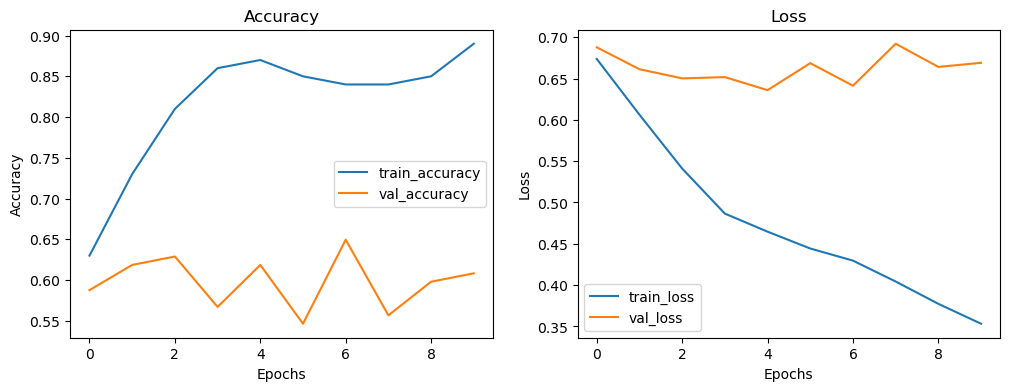

In [16]:
import matplotlib.pyplot as plt
# Plotting training and validation accuracy/loss
plt.figure(figsize=(12, 4))
 
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train_accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.title('Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
 
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title('Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
 
plt.show()

In [18]:
test_loss, test_acc = model.evaluate(test_data)
print(f'Test accuracy: {test_acc}')

/opt/anaconda3/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


 2/13 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.7812 - loss: 0.6370

/opt/anaconda3/lib/python3.12/site-packages/PIL/Image.py:3218: DecompressionBombWarning: Image size (104688771 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


 5/13 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.7596 - loss: 0.6514

/opt/anaconda3/lib/python3.12/site-packages/PIL/Image.py:3218: DecompressionBombWarning: Image size (89747104 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


13/13 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.6823 - loss: 0.6574
Test accuracy: 0.6082473993301392


In [19]:
train_loss, train_acc = model.evaluate(train_data)
print(f'Train accuracy: {train_acc}')

13/13 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.8771 - loss: 0.3607
Train accuracy: 0.8500000238418579


In [29]:
base_model.trainable = True
 
# Freeze the first few layers
for layer in base_model.layers[:50]:
    layer.trainable = False
 
# Recompile the model with a lower learning rate
model.compile(optimizer=Adam(learning_rate=0.00001), loss='binary_crossentropy', metrics=['accuracy'])
 
# Continue training
history_fine = model.fit(
    train_data,
    epochs=10,
    validation_data=validation_data)

Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 92s 6s/step - accuracy: 0.9014 - loss: 0.1797 - val_accuracy: 0.7732 - val_loss: 0.6775
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 69s 5s/step - accuracy: 0.9150 - loss: 0.1525 - val_accuracy: 0.7835 - val_loss: 0.6838
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 67s 5s/step - accuracy: 0.9950 - loss: 0.0531 - val_accuracy: 0.7835 - val_loss: 0.6715
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 67s 5s/step - accuracy: 1.0000 - loss: 0.0523 - val_accuracy: 0.7835 - val_loss: 0.6640
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 69s 5s/step - accuracy: 1.0000 - loss: 0.0480 - val_accuracy: 0.7835 - val_loss: 0.6727
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 70s 5s/step - accuracy: 0.9535 - loss: 0.2026 - val_accuracy: 0.7732 - val_loss: 0.6545
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 69s 6s/step - accuracy: 0.9574 - loss: 0.0657 - val_accuracy: 0.7629 - val_loss: 0.6535
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 68s 5s/step - accuracy: 0.9720 - loss: 0.0900 - val_accuracy: 0.7629 - val_loss:

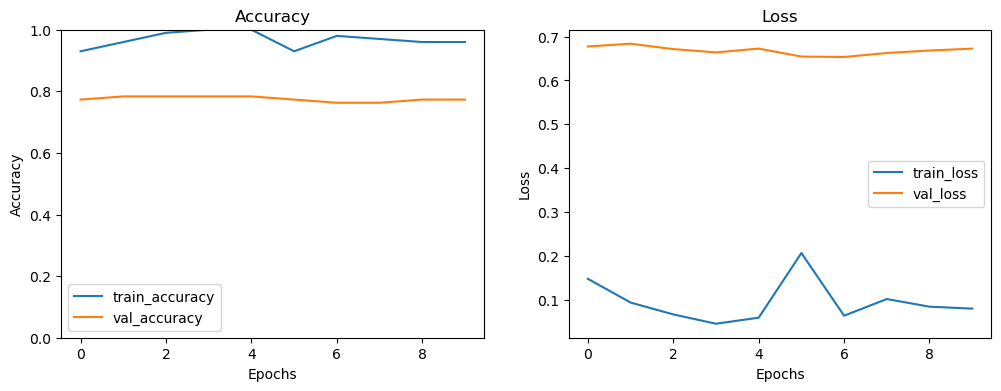

In [30]:
import matplotlib.pyplot as plt
# Plotting training and validation accuracy/loss
plt.figure(figsize=(12, 4))
 
plt.subplot(1, 2, 1)
plt.plot(history_fine.history['accuracy'], label='train_accuracy')
plt.plot(history_fine.history['val_accuracy'], label='val_accuracy')
plt.ylim([0,1])
plt.title('Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
 
plt.subplot(1, 2, 2)
plt.plot(history_fine.history['loss'], label='train_loss')
plt.plot(history_fine.history['val_loss'], label='val_loss')
plt.title('Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
 
plt.show()

In [31]:
train_loss, train_acc = model.evaluate(train_data)
print(f'Train accuracy: {train_acc}')

test_loss, test_acc = model.evaluate(test_data)
print(f'Test accuracy: {test_acc}')


13/13 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 1.0000 - loss: 0.0081
Train accuracy: 1.0
13/13 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.7773 - loss: 0.7042
Test accuracy: 0.7731958627700806
